# Example training script for your model

This week I will provide the training script in the form of a jupyter notebook for your model but in other weeks you may be expected to write this yourself or just use a plain python script. Again, I cannot stop you from using AI but I will consider anything you submit as fair game to ask questions on so make you understand what you or your assistant have written.

In [589]:
# DO NOT REMOVE THESE
# These two lines make sure any changes you make in scaffold.py
# are automatically reloaded each time you run a cell in this notebook.
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [590]:
import pandas as pd
import numpy as np

# * imports everything from scaffold.py
from scaffold import *
# Install sklearn as - scikit-learn
from sklearn.model_selection import train_test_split


In [591]:
data = pd.read_csv('data_train.csv')
# Split the data into training and test sets
# The reason we do this is so that we can evaluated the performance 
# on unseen data. If we just evaluated on the training data,
# we would not know if the model is overfitting or not. 
train_data, test_data = train_test_split(data, test_size=0.3, random_state=22, shuffle=False)
train_data = train_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)
print(f"Train data shape: {train_data.shape}")
print(f"Test data shape: {test_data.shape}")

Train data shape: (7000, 8)
Test data shape: (3000, 8)


In [592]:
features = [col for col in data.columns if col != 'y']
print(f"Features: {features}")

Features: ['x_1', 'x_2', 'x_3', 'x_4', 'x_5', 'x_6', 'x_7']


In [598]:
# Your model may need to be initialised in a different way.
model = Regression(degrees=[1,4], lmbda=0.1, normalize=False )

In [599]:
# Fit the parameters on the training data
model.fit(train_data[features], train_data['y'])
# You can adjust this to print the parameters in a different way if you want.
# This may not be the most informative.
print(f"Model parameters: {model.theta}")

Model parameters: [ 2.33391174e+01  1.91106980e+00 -1.94431804e+00 -3.01242976e-01
  4.01975398e-01 -2.14211461e-01 -4.63811284e-01 -6.75943841e-01
 -8.38768458e-09  3.11748641e-08 -6.90758704e-08 -1.19584321e-07
  3.43139407e-08  1.61183906e-07 -4.52864430e-07]


In [600]:
# Create predictions for the training data
predictions_train = model.predict(train_data[features])

# Score those predictions on the training data
# We will just use MSE (mean squared error) as the metric for now.
mse_train = np.sqrt(np.mean((predictions_train - train_data['y'])**2))
print(f"Training MSE: {mse_train}")

Training MSE: 7.173238543359682


In [601]:
# Create predictions for the test data.
predictions = model.predict(test_data[features])


# Score those predictions on the test data
# Again using the MSE as the metric for now.
mse_test = np.sqrt(np.mean((predictions - test_data['y'])**2))
print(f"Test MSE: {mse_test}")
print(f"Delta MSE: {mse_train-mse_test}")

Test MSE: 7.944671121867461
Delta MSE: -0.7714325785077785


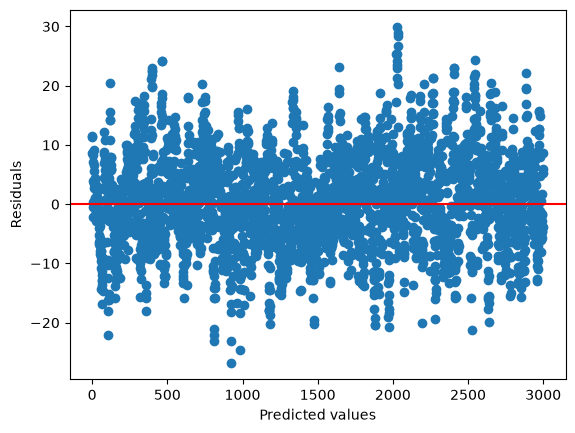

In [602]:
# You may want to plot the residuals to see if there are any patterns 
# your model is not capturing. This can be a good way to debug your model.
import matplotlib.pyplot as plt

residuals = predictions - test_data["y"].to_numpy()
plt.scatter(np.arange(len(predictions)), residuals)
plt.axhline(y=0, color="r")
plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.show()



## Submitting to a hidden validation set
There is an online validation that runs in your browser. Here you can compare your result vs your coursemates and also vs 3 baselines I have uploaded previously.

To upload: Use only scaffold.py and make sure your model class is named Regression. 

Naming: I suggest not using your full name to upload here as it is a public website.

Good luck!